# Breast Cancer Classification Using Machine Learning

## 1. Project Idea

This project uses machine learning to classify breast tumors as benign or malignant based on numerical measurements computed from cell images.

The Wisconsin Diagnostic Breast Cancer dataset contains features such as radius, texture, perimeter, area, and smoothness.

Two classification algorithms, Decision Tree and K-Nearest Neighbors (KNN), will be trained and evaluated using accuracy scores and confusion matrices.

**Objective:** Learn the basic machine learning workflow, including data preparation, model building, evaluation, and comparison.

**Disclaimer:** This project is for educational purposes only and is not intended for medical diagnosis.

In [2]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [7]:
# Load the Wisconsin Diagnostic Breast Cancer dataset
cancer = load_breast_cancer()

X = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Convert target labels into readable class names
y = pd.Series(cancer.target).map({
    0: "Malignant",
    1: "Benign"
})

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Dataset loaded successfully!
Features shape: (569, 30)
Target shape: (569,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Data Preparation

We will inspect the dataset, check for missing values, examine the target classes, and split the data into training and testing sets.

The features are numerical. KNN is sensitive to differences in feature scales, so we will standardize its input features as part of the preprocessing pipeline.

In [8]:
# Inspect the dataset
print("Dataset information:")
print(X.info())

print("\nMissing values in each feature:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

print("\nTarget class distribution:")
print(y.value_counts())

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

## 3. Model Building

### Model 1: Decision Tree

A Decision Tree learns rules based on feature values and uses them to classify a tumor. It can model nonlinear relationships and does not require feature scaling.

In [9]:
decision_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=42))
])

# Train the model
decision_tree.fit(X_train, y_train)

# Predict test data
dt_predictions = decision_tree.predict(X_test)

# Evaluate accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)

print(f"Decision Tree Accuracy: {dt_accuracy * 100:.2f}%")

Decision Tree Accuracy: 92.98%


### Model 2: K-Nearest Neighbors (KNN)

KNN predicts the class of a new sample by examining the five nearest samples in the training set. Since the dataset has features measured on different numerical scales, standardization is important for fair distance calculations.

In [10]:
knn = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn.fit(X_train, y_train)

# Predict test data
knn_predictions = knn.predict(X_test)

# Evaluate accuracy
knn_accuracy = accuracy_score(y_test, knn_predictions)

print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%")

KNN Accuracy: 95.61%


In [11]:
results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy (%)": [
        dt_accuracy * 100,
        knn_accuracy * 100
    ]
})

display(results)

if dt_accuracy > knn_accuracy:
    print("Decision Tree performed better on this test set.")
elif knn_accuracy > dt_accuracy:
    print("KNN performed better on this test set.")
else:
    print("Both models achieved the same accuracy.")

,Model,Accuracy (%)
0,Decision Tree,92.982456
1,KNN,95.614035


KNN performed better on this test set.


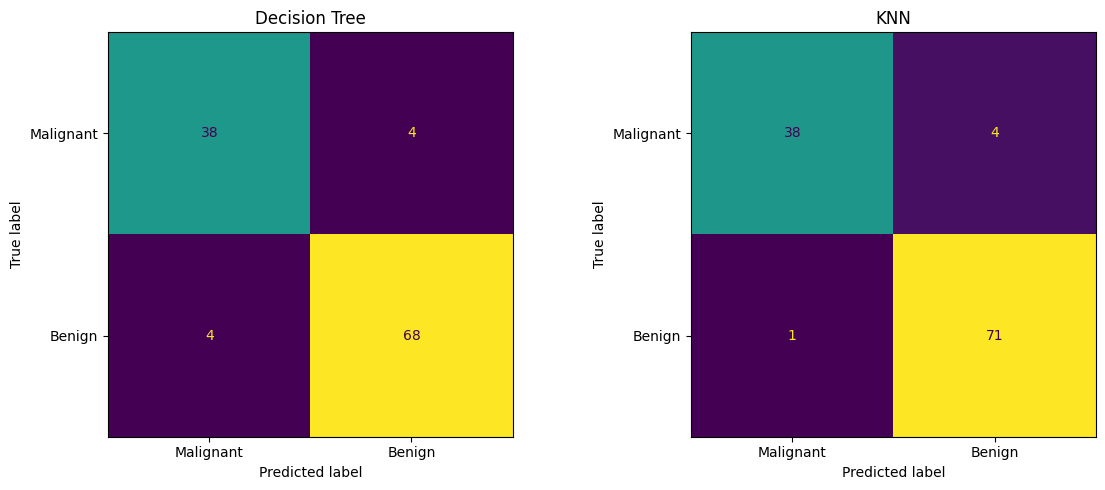

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_predictions,
    labels=["Malignant", "Benign"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Decision Tree")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_predictions,
    labels=["Malignant", "Benign"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("KNN")

plt.tight_layout()
plt.show()

In [13]:
better_model = (
    "Decision Tree" if dt_accuracy > knn_accuracy
    else "KNN" if knn_accuracy > dt_accuracy
    else "Both models performed equally"
)

print("PROJECT CONCLUSION")
print("------------------")
print(f"Decision Tree accuracy: {dt_accuracy * 100:.2f}%")
print(f"KNN accuracy: {knn_accuracy * 100:.2f}%")
print(f"Better-performing model: {better_model}")

PROJECT CONCLUSION
------------------
Decision Tree accuracy: 92.98%
KNN accuracy: 95.61%
Better-performing model: KNN


## 5. Conclusion

In this project, I built and evaluated two machine learning classification models using the Wisconsin Diagnostic Breast Cancer dataset.

The dataset contained 569 samples with 30 numerical features. I checked for missing values, separated the features and target, and divided the data into training and testing sets.

The Decision Tree model achieved an accuracy of 92.98%, while K-Nearest Neighbors (KNN) achieved 95.61%. Therefore, KNN performed better on this particular test set.

The confusion matrices helped me understand the correct and incorrect predictions made by both models. I also learned why feature standardization is important for distance-based algorithms such as KNN, while Decision Trees generally do not require it.

This project helped me understand the basic machine learning workflow, including data preparation, model training, prediction, and evaluation.

**Limitation:** These results are from a single train-test split and do not establish clinical reliability. This project is for educational purposes only and must not be used for medical diagnosis.